In [99]:
import numpy as np
import numba as nb
import scipy.stats as stats
import torch
import matplotlib.pyplot as plt
import pickle
import h5py
import re
import yaml
import torch.distributions as dists
from omegaconf import OmegaConf

from sbi import utils as utils
from sbi import analysis as analysis
from sbi.utils.user_input_checks import MultipleIndependent
from sbi.utils.user_input_checks import process_simulator
from sbi.inference.potentials import ratio_estimator_based_potential
from sbi.inference.posteriors import MCMCPosterior
from sbi.simulators.simutils import simulate_in_batches

In [100]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from simulator import smFRET_simulator_wrapper_from_config, binding_simulator_wrapper_from_config
from priors import generate_posterior_prior_from_config
from utils import eval_free_energy_from_config, eval_force_from_config

In [101]:
def bin_along_time(x, n_bins=100):
    n = len(x)
    n_per_bin = int(n / n_bins)
    x_binned = np.zeros(n_bins)
    for i in range(n_bins):
        x_binned[i] = np.sum(x[i*n_per_bin:(i+1)*n_per_bin])
    return x_binned

In [102]:
cfg_path = "/home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/exp_2/2026-04-03/19-41-31/"
data_cfg = cfg_path + "data_config.yaml"
device = "cuda" if torch.cuda.is_available() else "cpu"

In [103]:
prior = generate_posterior_prior_from_config(data_cfg, device=device)
eval_force = eval_force_from_config(data_cfg)
eval_free_energy = eval_free_energy_from_config(data_cfg)
data_cfg = OmegaConf.load(data_cfg)

if data_cfg.simulator.mode == "equilibrium":
    fret_simulator = smFRET_simulator_wrapper_from_config(data_cfg)
elif data_cfg.simulator.mode == "binding":
    _fret_simulator = binding_simulator_wrapper_from_config(data_cfg)
    
    def fret_simulator(params):
        trajectory, length = _fret_simulator(params)
        return trajectory

In [104]:
true_params = torch.tensor([-1.0, -3.0, -1.5, -0.0, 1.5, 3.0, 6.0, 400.00, 0.0100,  0.01000,  0.9500,  0.9500,  0.9000,  0.9000,  0.1000,  0.1000], dtype=torch.float64)
#true_params = torch.tensor([0.1, -.5, -0.5, -0.5, 0.2, 0.2, 1.0,  7, 2.00, 0.0100,  0.01000,  0.9500,  0.9500,  0.9000,  0.9000,  0.1000,  0.1000], dtype=torch.float64)
#true_params = torch.tensor([0.1, -.5, -0.5, -0.5, 0.2, 0.2, 1.0,  7, 2.00, 0.0100,  0.01000,  0.9500,  0.9500,  0.9000,  0.9000,  0.1000,  0.1000], dtype=torch.float64)

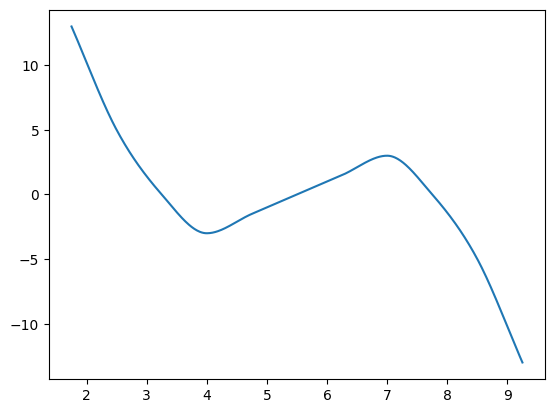

In [105]:
knot_spacing = (data_cfg.simulator.x_max - data_cfg.simulator.x_min) / (data_cfg.prior.num_knots - 1)
x_plot_margin = 0.6 * data_cfg.simulator.num_boundary_knots * knot_spacing
x_eval = np.linspace(data_cfg.simulator.x_min - x_plot_margin, data_cfg.simulator.x_max + x_plot_margin, 500)

x, y = eval_force(
    params=true_params,
    x_eval=x_eval,
)
plt.plot(x, y)

(0.0, 10.0)

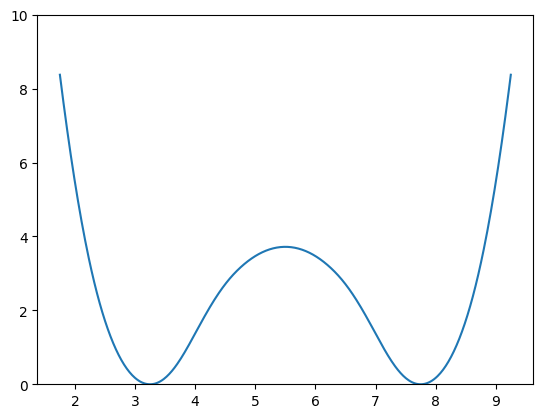

In [106]:
x, y = eval_free_energy(
    params=true_params,
    x_eval=x_eval,
)
plt.plot(x, y - np.min(y))
plt.ylim(0, 10)

In [117]:
from multiprocessing import Pool
import os

def _init_worker():
    np.random.seed(os.getpid())  # unique seed per worker so x_init differs

with Pool(processes=10, initializer=_init_worker) as pool:
    raw = pool.map(_fret_simulator, [true_params] * 1000)
results = [r[0] for r in raw if r is not None][:20]
observation = torch.stack(results)

Text(0.5, 0, 'Time')

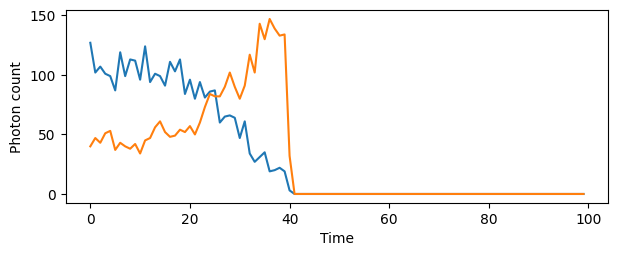

In [118]:
idx = 11
plt.figure(figsize=(7, 2.5))
plt.plot(bin_along_time(observation[idx, :, 0].numpy(), n_bins=100), label="Donor")
plt.plot(bin_along_time(observation[idx, :, 1].numpy(), n_bins=100), label="acceptor")
plt.ylabel("Photon count")
plt.xlabel("Time")


In [109]:
try:
    with open(cfg_path + "ratio_estimator.pkl", "rb") as f:
        ratio_estimator = pickle.load(f)
except FileNotFoundError:
    with open(cfg_path + "last_ratio_estimator.pkl", "rb") as f:
        ratio_estimator = pickle.load(f)

ratio_estimator.eval();

In [110]:
potential, tf = ratio_estimator_based_potential(ratio_estimator, prior, observation.cuda())
posterior = MCMCPosterior(
    potential,
    proposal=prior,
    theta_transform=tf,
    num_chains=10,
    thin=2,
    method="slice_np_vectorized",
)

In [111]:
import types
import math

# Pre-compute the x_o embedding once — avoids re-running embedding_net_x at every MCMC step
with torch.no_grad():
    x_o_embedded = ratio_estimator.embedding_net_x(
        observation.cuda().reshape(-1, *ratio_estimator.x_shape)
    )  # shape: (n_iid, embed_dim)

ratio_estimator._x_cached_embedded = x_o_embedded

# Save original method so we can fall back to it when shapes don't align
# (e.g. during init strategy where theta arrives in unexpected batch shapes)
_original_combine = ratio_estimator.__class__.combine_theta_and_x

def _fast_combine(self, theta, x):
    """combine_theta_and_x with cached x embedding.

    Falls back to the original (full re-embedding) when the theta tensor's
    element count isn't divisible by prod(theta_shape), which can happen
    during the init strategy phase of MCMC.
    """
    theta_shape_size = math.prod(self.theta_shape)
    n_iid = self._x_cached_embedded.shape[0]

    if theta.numel() % theta_shape_size != 0:
        # Shape mismatch — fall back to original (re-embeds x from scratch)
        return _original_combine(self, theta, x)

    n = theta.numel() // theta_shape_size
    if n % n_iid != 0:
        return _original_combine(self, theta, x)

    # Fast path: use cached x embedding
    # SBI repeats x as AABBCC (repeat_interleave) and theta as ABCABC,
    # so we must mirror that pattern for the cached embedding.
    embedded_theta = self.embedding_net_theta(theta.reshape(n, *self.theta_shape))
    embedded_x = self._x_cached_embedded.repeat_interleave(n // n_iid, dim=0)
    prefix_shape = theta.shape[: -len(self.theta_shape)]
    return torch.cat([embedded_theta, embedded_x], dim=-1).reshape(*prefix_shape, -1)

ratio_estimator.combine_theta_and_x = types.MethodType(_fast_combine, ratio_estimator)

potential, tf = ratio_estimator_based_potential(ratio_estimator, prior, observation.cuda())
posterior = MCMCPosterior(
    potential,
    proposal=prior,
    theta_transform=tf,
    num_chains=50,
    thin=2,
    method="slice_np_vectorized",
)

In [112]:
samples = posterior.sample(
    (5000,), 
    x=observation.cuda(),
    init_strategy_parameters={'num_candidate_samples': 1000},
).cpu()

Running vectorized MCMC with 50 chains: 100%|██████████| 32500/32500 [00:44<00:00, 734.77it/s]


In [113]:
map_estimate = posterior.map(
    num_iter=6000,
    num_init_samples=1000,
    learning_rate=0.0001,
    show_progress_bars=True,
    force_update=True
)

 Optimizing MAP estimate. Iterations: 6000 / 6000. Performance in iteration 6000: 10.70 (= unnormalized log-prob). Press Ctrl-C to interrupt.

/tmp/ipykernel_3915948/1374595667.py:1: DeprecationWarning: you passed deprecated arguments **kwargs: ['points_offdiag', 'points_colors'], use fig_kwargs instead. We continue calling the deprecated pairplot function
  _ = analysis.pairplot(


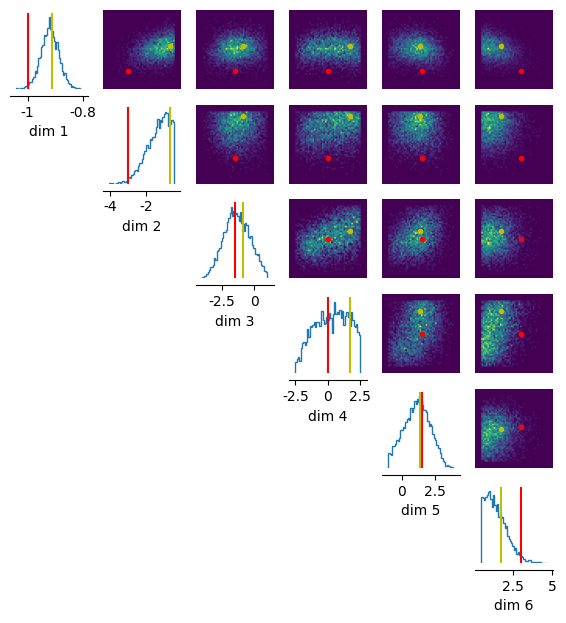

In [114]:
_ = analysis.pairplot(
    samples,
    figsize=(7,7),
    points=[true_params, map_estimate[0].cpu()], 
    points_offdiag={'markersize': 6},
    points_colors=['r', 'y'], 
)

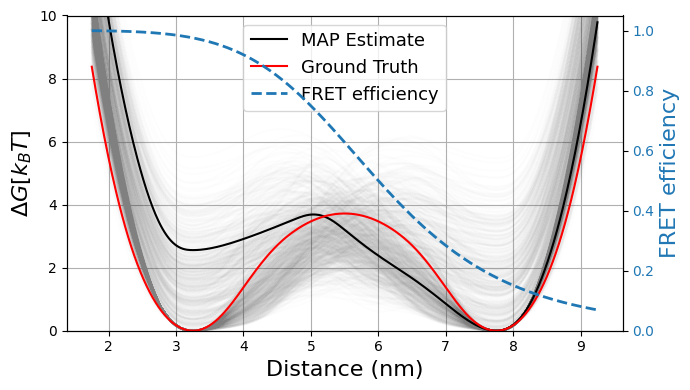

In [115]:
x_min, x_max = -2, 21

fig, ax1 = plt.subplots(figsize=(7, 4))

# Free-energy samples
for i in range(1000):
    x, y = eval_free_energy(
        params=samples[i],
        x_eval=x_eval,
    )
    ax1.plot(x, y - y.min(), color="gray", alpha=0.01)

# MAP free-energy
x, y = eval_free_energy(
    params=map_estimate[0].cpu(),
    x_eval=x_eval,
)
ax1.plot(x, y - y.min(), color="black", label="MAP Estimate")

# Ground-truth free-energy
x, y = eval_free_energy(
    params=true_params,
    x_eval=x_eval,
)
ax1.plot(x, y - y.min(), color="r", label="Ground Truth")

ax1.set_xlabel("Distance (nm)", fontsize=16)
ax1.set_ylabel(r"$\Delta G [k_{B}T]$", fontsize=16)
ax1.set_ylim(0, 10)
ax1.grid()

# Secondary axis: FRET efficiency
ax2 = ax1.twinx()
R0 = float(true_params[6])  # uses your existing parameter vector
r = np.clip(x_eval, 1e-9, None)
E = 1.0 / (1.0 + (r / R0) ** 6)
E[x_eval <= 0] = np.nan  # hide non-physical negative distances

ax2.plot(x_eval, E, color="tab:blue", linestyle="--", linewidth=2, label="FRET efficiency")
ax2.set_ylabel("FRET efficiency", color="tab:blue", fontsize=16)
ax2.set_ylim(0, 1.05)
ax2.tick_params(axis="y", labelcolor="tab:blue")

# Combined legend
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=13, loc="best")

plt.tight_layout()

(array([  4.,   1.,   7.,  12.,  22.,  26.,  56.,  82., 117., 154., 239.,
        303., 383., 440., 457., 547., 452., 398., 338., 327., 219., 141.,
         99.,  78.,  40.,  24.,  19.,   7.,   3.,   5.]),
 array([-1.0406909 , -1.03284526, -1.02499962, -1.01715398, -1.00930834,
        -1.0014627 , -0.993617  , -0.98577136, -0.97792572, -0.97008008,
        -0.96223444, -0.9543888 , -0.9465431 , -0.93869746, -0.93085182,
        -0.92300618, -0.91516054, -0.9073149 , -0.89946926, -0.89162356,
        -0.88377792, -0.87593228, -0.86808664, -0.860241  , -0.85239536,
        -0.84454972, -0.83670408, -0.82885838, -0.82101274, -0.8131671 ,
        -0.80532146]),
 <BarContainer object of 30 artists>)

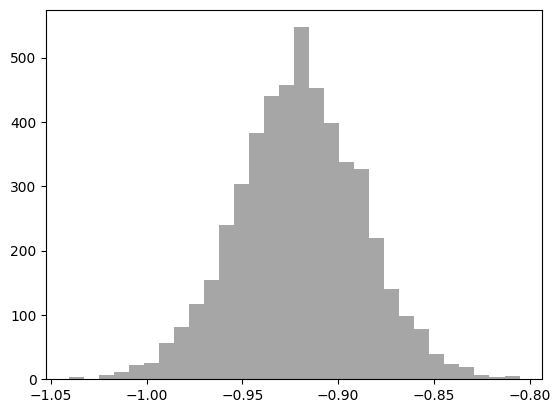

In [116]:
plt.hist(samples[:, 0].cpu(), bins=30, color="gray", alpha=0.7)